# RQ1A — GDP dispersion between EU NUTS 2 regions

**Author:** Morné Magerman · EU Regional Convergence project (Data Analytics)

**Question:** Is the GDP spread narrowing year by year?

This notebook runs the shared `src/rq1a_dispersion.py` analysis and exports figures, tables, and detailed Markdown interpretation for the team Quarto report. It does not implement RQ2–RQ4.

## 1. Imports and repository paths
Run from the repository in Positron or Jupyter. The code locates the project root by searching for `src/rq1a_dispersion.py`, regardless of the notebook working directory.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Markdown, Image

def locate_root():
    cwd = Path.cwd().resolve()
    for candidate in [cwd, *cwd.parents, cwd / "RQ1A_Repository_Contribution"]:
        if (candidate / "src" / "rq1a_dispersion.py").exists():
            return candidate
    raise FileNotFoundError("Cannot locate src/rq1a_dispersion.py. Open the notebook inside the repository.")

ROOT = locate_root()
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.rq1a_dispersion import main
INPUT = ROOT / "data" / "eu_nuts2_master_panel.csv"
OUTPUT = ROOT / "outputs" / "rq1a"
print("Project:", ROOT)
print("Input:", INPUT)
print("Output:", OUTPUT)

Project: /mnt/data/RQ1A_Repository_Contribution
Input: /mnt/data/RQ1A_Repository_Contribution/data/eu_nuts2_master_panel.csv
Output: /mnt/data/RQ1A_Repository_Contribution/outputs/rq1a


## 2. Run the reproducible RQ1A pipeline
Calculates annual CV, sample standard deviation, P90–P10 gap, indexed series, period comparisons, outlier and flag sensitivity checks, and writes detailed interpretation.

In [2]:
main(INPUT, OUTPUT)

Observations: 2196; regions: 244; years: 2016–2024.
Balanced region-year structure: True. Missing GDP values: 0.
GDP flags (all years): {'none': 1692, 'p': 433, 'b': 38, 'e': 33}
Important: A balanced panel and stable region codes DO NOT establish harmonized NUTS boundary definitions.
Check Eurostat vintage, NUTS classification, retroactive revisions, and data provenance externally.
All main statistics are unweighted across regions. SD is sample SD (ddof=1).
GDP is an index, not GDP in euros; SD and percentile gaps are index points.
Period comparisons use start/end levels, not average annual measures.
Annual top-1% trimming changes the sample and is a sensitivity test, not a replacement.
Unflagged-only comparison changes sample composition; interpret with caution.
Descriptive results do not establish causes of widening/narrowing.

Main results:
2016: CV=39.77%; SD=37.56; P90-P10=88.70; IQR=48.25
2017: CV=39.51%; SD=37.25; P90-P10=90.10; IQR=47.50
2018: CV=39.27%; SD=36.98; P90-P10=90.7

## 3. Annual dispersion and year-on-year changes

In [3]:
annual = pd.read_csv(OUTPUT / "annual_dispersion_enhanced.csv")
display(annual[["year", "n_regions", "cv_pct", "sd", "p90_p10_gap", "cv_pct_change", "sd_change", "p90_p10_gap_change"]].round(2))

,year,n_regions,cv_pct,sd,p90_p10_gap,cv_pct_change,sd_change,p90_p10_gap_change
0,2016,244,39.77,37.56,88.7,NaN,NaN,NaN
1,2017,244,39.51,37.25,90.1,-0.27,-0.31,1.4
2,2018,244,39.27,36.98,90.7,-0.24,-0.27,0.6
3,2019,244,38.57,36.23,85.7,-0.70,-0.74,-5.0
4,2020,244,39.43,37.15,85.7,0.86,0.92,0.0
5,2021,244,39.69,37.35,83.0,0.26,0.20,-2.7
6,2022,244,39.93,37.67,84.0,0.24,0.32,1.0
7,2023,244,38.02,35.81,79.4,-1.90,-1.86,-4.6
8,2024,244,37.96,35.69,75.7,-0.07,-0.12,-3.7


## 4. Figure 1 — Indexed dispersion (2016 = 100)
A common baseline compares proportional changes across indicators with different units.

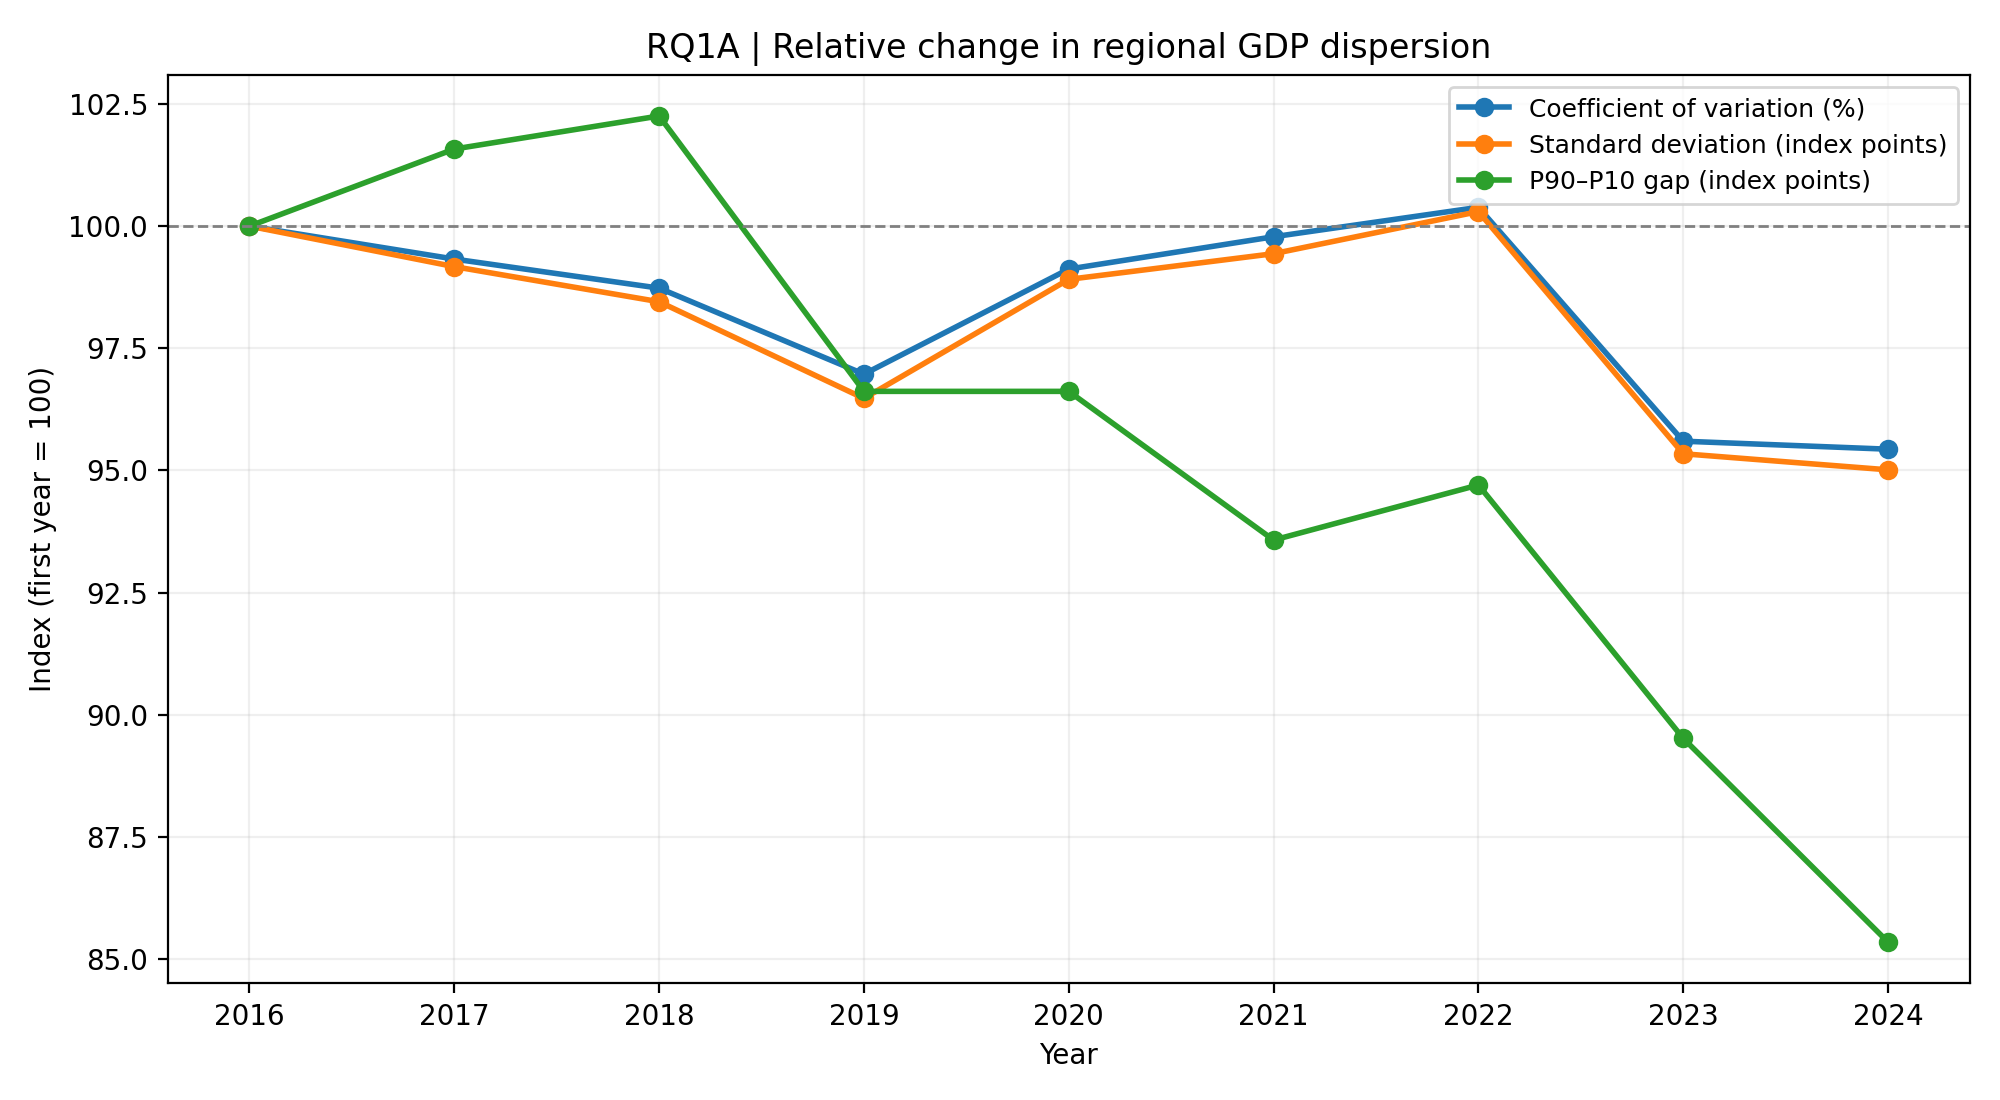

In [4]:
display(Image(filename=str(OUTPUT / "figure_1_indexed_dispersion.png")))

## 5. Figure 2 — Annual GDP distribution boxplots
The boxplots show the median, IQR, whiskers, and extreme observations.

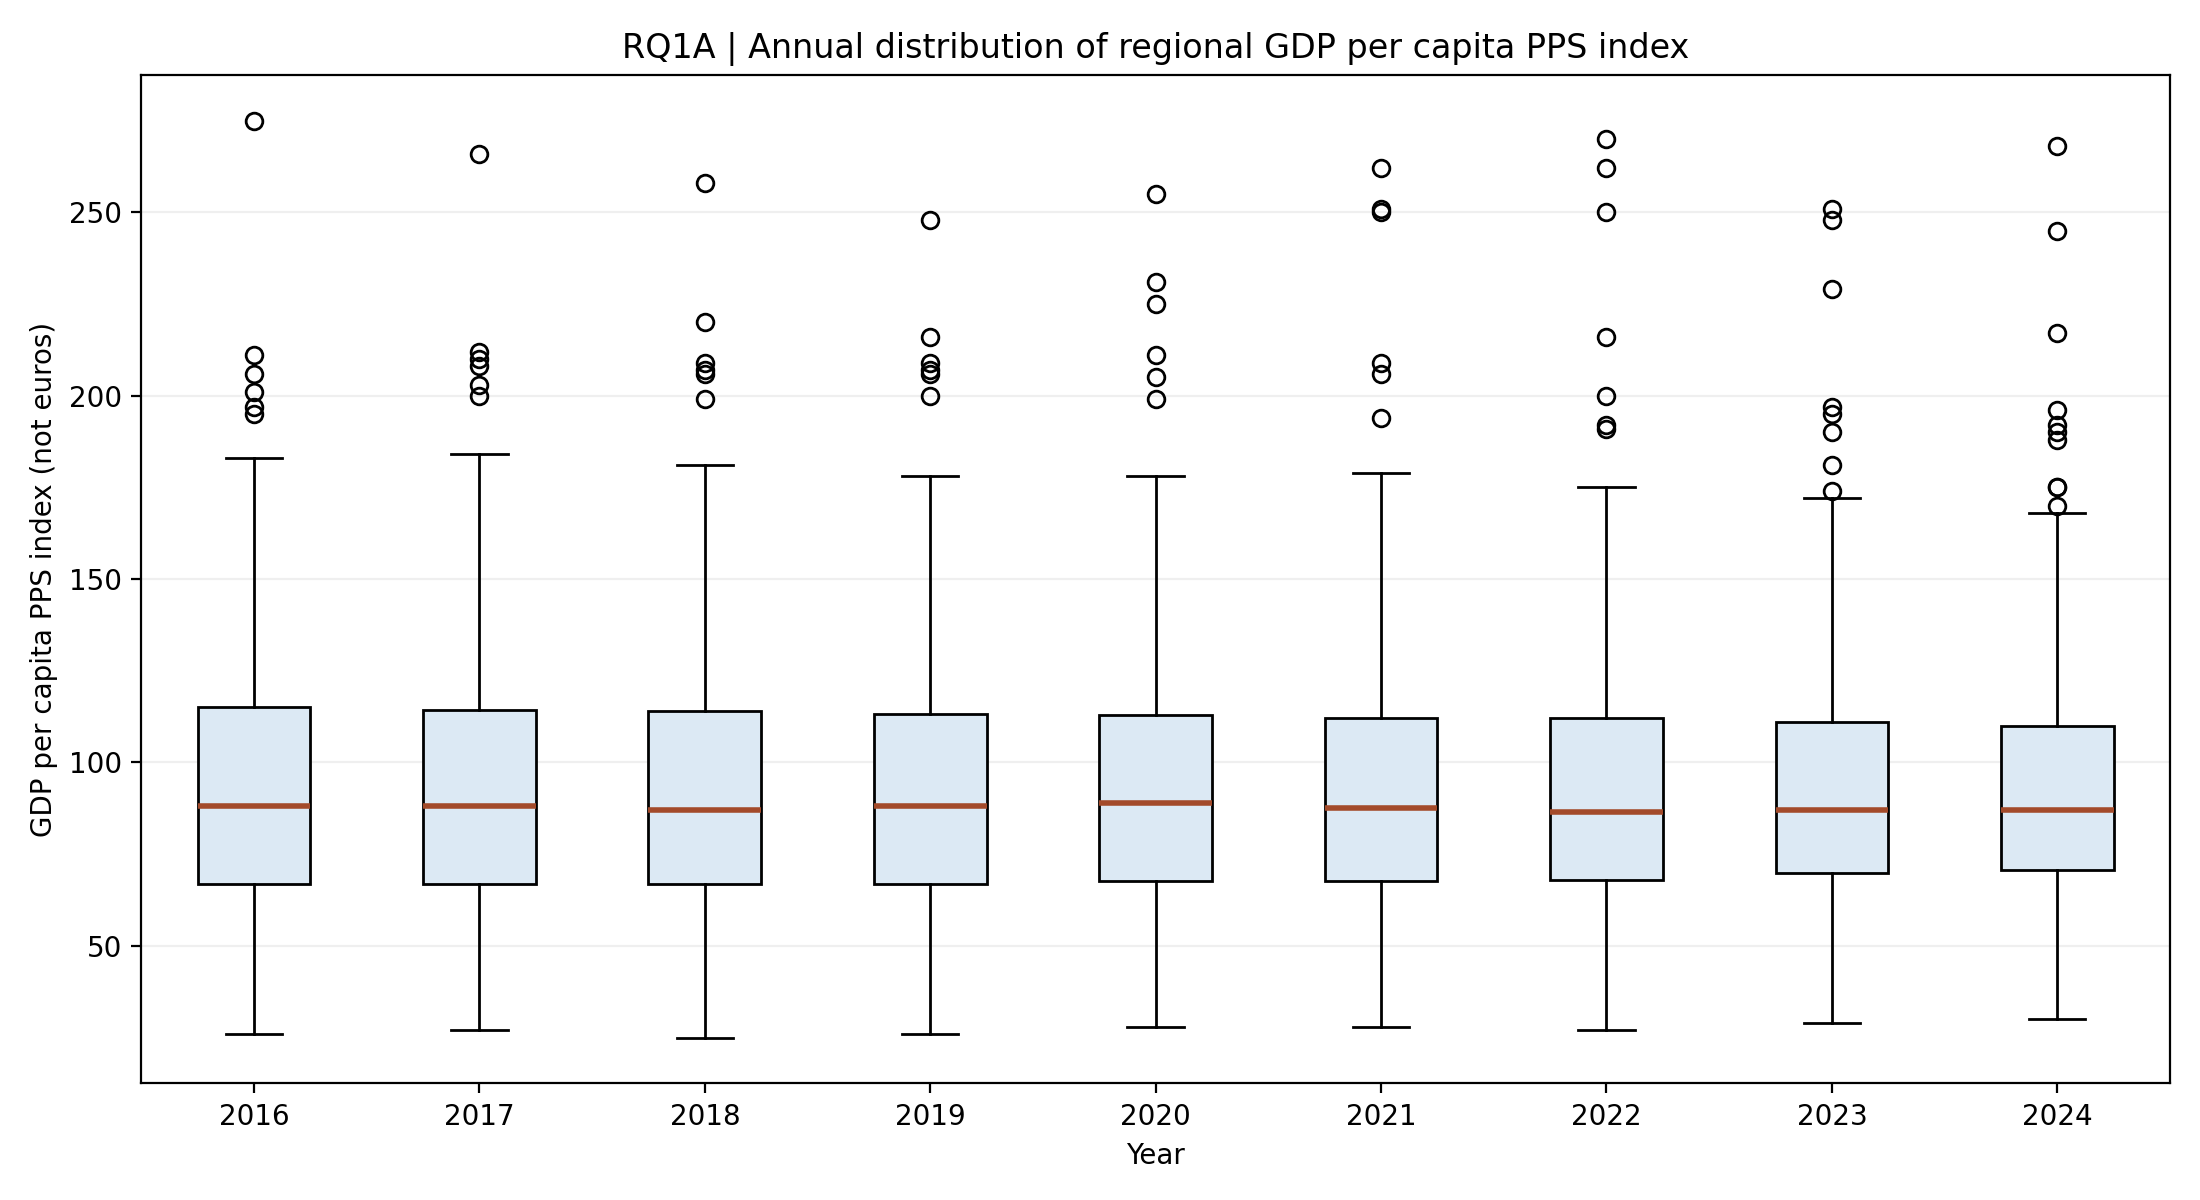

In [5]:
display(Image(filename=str(OUTPUT / "figure_2_annual_boxplots.png")))

## 6. Period comparison

In [6]:
display(pd.read_csv(OUTPUT / "period_comparisons.csv").round(2))

,period,start_year,end_year,elapsed_years,cv_pct_start,cv_pct_end,cv_pct_absolute_change,cv_pct_relative_change_pct,sd_start,sd_end,sd_absolute_change,sd_relative_change_pct,p90_p10_gap_start,p90_p10_gap_end,p90_p10_gap_absolute_change,p90_p10_gap_relative_change_pct
0,2016–2019,2016,2019,3,39.77,38.57,-1.21,-3.03,37.56,36.23,-1.32,-3.53,88.7,85.7,-3.0,-3.38
1,2019–2022,2019,2022,3,38.57,39.93,1.36,3.52,36.23,37.67,1.44,3.96,85.7,84.0,-1.7,-1.98
2,2022–2024,2022,2024,2,39.93,37.96,-1.97,-4.93,37.67,35.69,-1.99,-5.27,84.0,75.7,-8.3,-9.88


## 7. Figure 3 — Outlier sensitivity

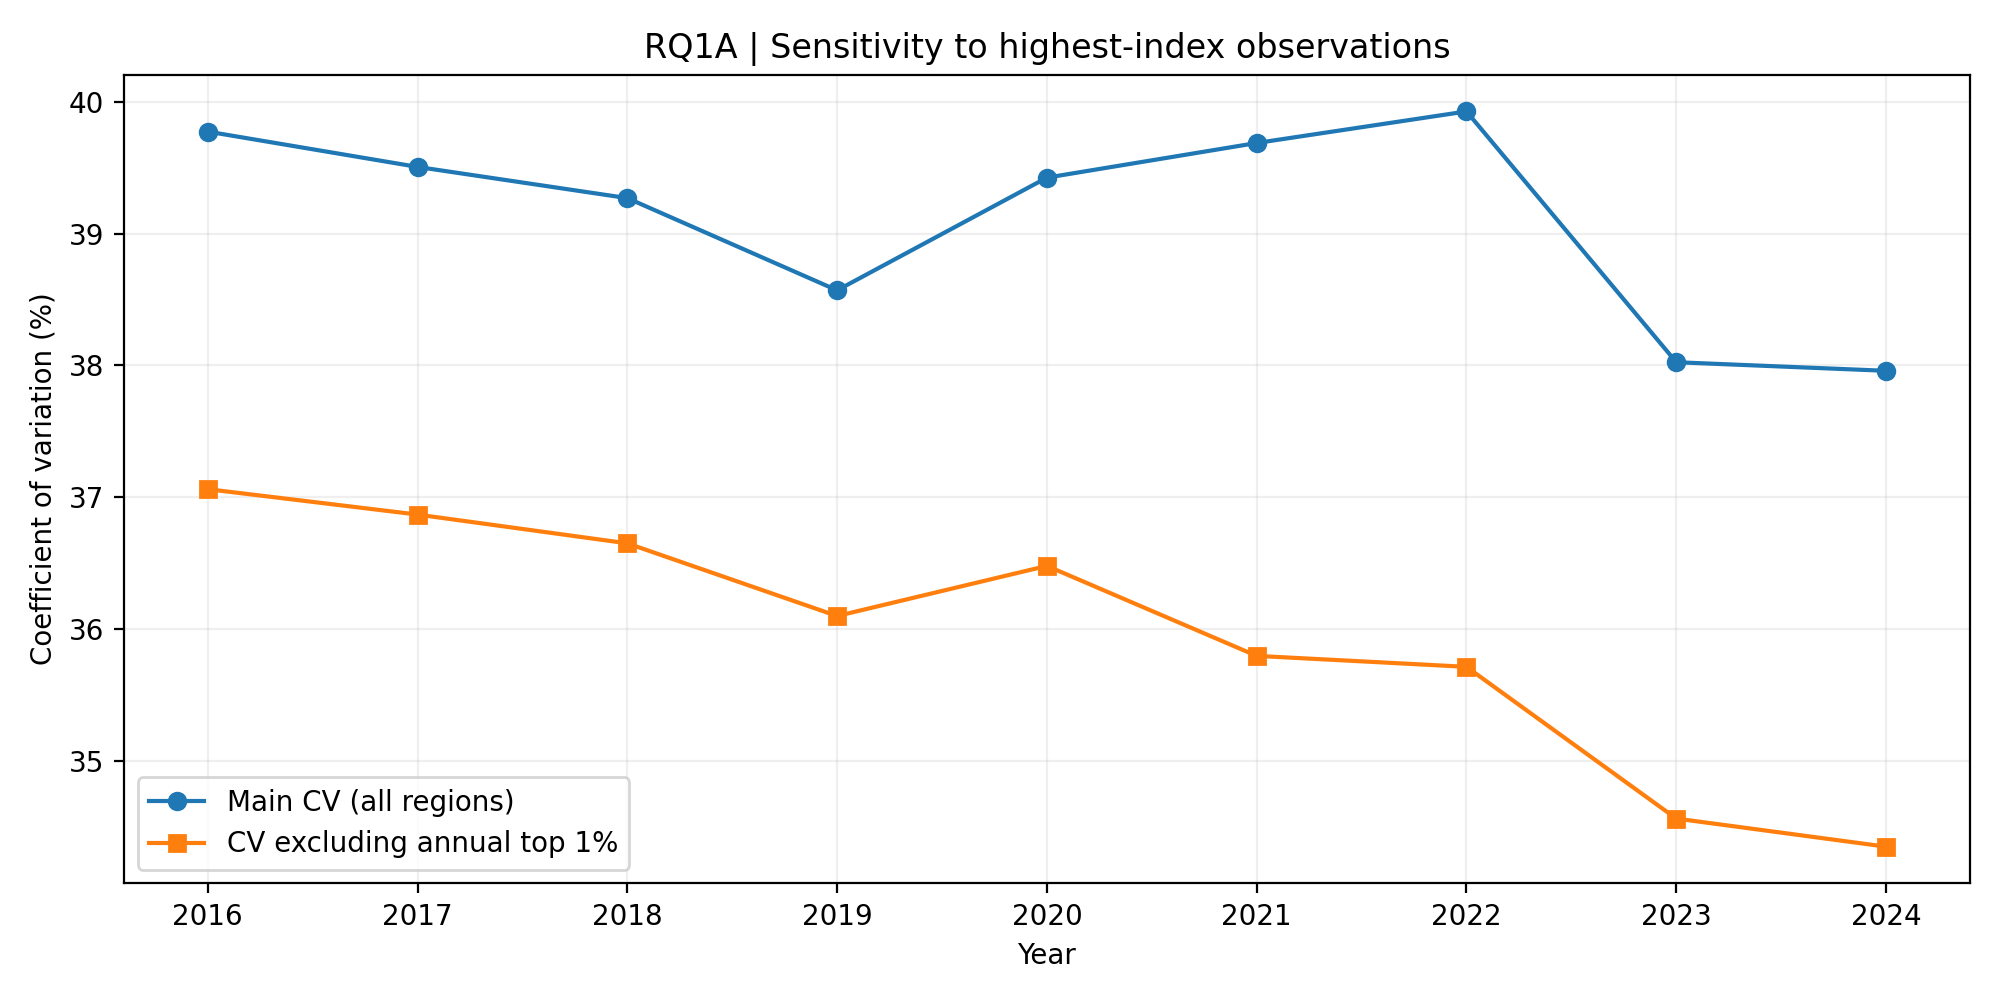

,year,n_regions_main,cv_pct_main,sd_main,p90_p10_gap_main,iqr,n_regions_trim_top_1pct,cv_pct_trim_top_1pct,sd_trim_top_1pct,p90_p10_gap_trim_top_1pct,cv_difference_pp
0,2016,244,39.77,37.56,88.7,48.25,241,37.06,34.37,86.0,-2.71
1,2017,244,39.51,37.25,90.1,47.50,241,36.87,34.14,86.0,-2.64
2,2018,244,39.27,36.98,90.7,47.00,241,36.65,33.89,87.0,-2.62
3,2019,244,38.57,36.23,85.7,46.25,241,36.10,33.33,83.0,-2.47
4,2020,244,39.43,37.15,85.7,45.25,241,36.48,33.72,82.0,-2.95
5,2021,244,39.69,37.35,83.0,44.50,241,35.79,32.97,81.0,-3.89
6,2022,244,39.93,37.67,84.0,44.00,241,35.71,32.95,78.0,-4.22
7,2023,244,38.02,35.81,79.4,41.25,241,34.56,31.91,76.0,-3.46
8,2024,244,37.96,35.69,75.7,39.25,241,34.35,31.65,74.0,-3.61


In [7]:
display(Image(filename=str(OUTPUT / "figure_3_outlier_sensitivity.png")))
display(pd.read_csv(OUTPUT / "outlier_sensitivity.csv").round(2))

## 8. Panel quality, flags and unflagged-only sensitivity
Balanced observed codes do **not** establish NUTS boundary harmonisation.

In [8]:
display(pd.read_csv(OUTPUT / "panel_completeness.csv"))
display(pd.read_csv(OUTPUT / "gdp_flags_by_year.csv"))
display(pd.read_csv(OUTPUT / "unflagged_only_sensitivity.csv").round(2))

,year,n_rows,n_regions,missing_gdp
0,2016,244,244,0
1,2017,244,244,0
2,2018,244,244,0
3,2019,244,244,0
4,2020,244,244,0
5,2021,244,244,0
6,2022,244,244,0
7,2023,244,244,0
8,2024,244,244,0


,year,b,e,none,p,total,missing_gdp
0,2016,0,0,231,13,244,0
1,2017,0,0,231,13,244,0
2,2018,0,0,231,13,244,0
3,2019,0,0,231,13,244,0
4,2020,17,0,214,13,244,0
5,2021,4,0,189,51,244,0
6,2022,17,0,149,78,244,0
7,2023,0,0,147,97,244,0
8,2024,0,33,69,142,244,0


,year,n_regions,cv_pct,sd,p90_p10_gap
0,2016,231,38.84,37.47,87.0
1,2017,231,38.50,37.10,88.0
2,2018,231,38.19,36.77,92.0
3,2019,231,37.41,35.95,86.0
4,2020,214,37.42,36.86,85.4
5,2021,189,40.32,37.29,80.0
6,2022,149,41.62,40.62,90.4
7,2023,147,41.39,39.72,94.6
8,2024,69,31.26,30.35,71.2


## 9. Detailed explanations for the team report
The Markdown below is generated from the same calculations as the figures. It is saved as `outputs/rq1a/rq1a_detailed_explanations.md` for Quarto integration.

In [9]:
narrative = (OUTPUT / "rq1a_detailed_explanations.md").read_text(encoding="utf-8")
# The Markdown image links are relative to the output directory; view images in sections above.
display(Markdown(narrative.replace("(figure_", f"({OUTPUT.as_posix()}/figure_")))

# RQ1A — Is the GDP spread narrowing year by year?

## Scope and measurement

This section measures **sigma convergence**: whether the cross-sectional dispersion of GDP per capita (PPS index) across NUTS 2 regions decreases over time. It does **not** test whether initially poorer regions subsequently grow faster (beta convergence), explain industrial or geographical differences, or reconcile the two convergence tests. Those questions are reserved for other workstreams.

The dataset contains **2,196 region-year observations**, **244 unique regions**, and **9 years (2016–2024)**. Each region receives equal weight. The standard deviation uses the sample formula (ddof=1). CV is SD divided by the cross-sectional mean, multiplied by 100. P90–P10 subtracts the annual 10th percentile from the annual 90th percentile. SD and percentile gaps are in **PPS index points, not euros**. Negative changes in dispersion indicate narrowing; positive changes indicate widening. These descriptive statistics do not identify causes.

## Figure 1. Indexed dispersion indicators

![Figure 1. Three dispersion indicators indexed to the first year = 100](/mnt/data/RQ1A_Repository_Contribution/outputs/rq1a/figure_1_indexed_dispersion.png)

**What the figure shows.** The coefficient of variation, standard deviation and P90–P10 gap are rescaled to **2016 = 100** to permit comparison of their proportional movement despite different original units. An index below 100 indicates less dispersion than in the base year; above 100 indicates more. Indexing does not alter the underlying values or their direction of change.

**Results.** The coefficient of variation narrowed from 39.77% in 2016 to 37.96% in 2024 (change: -1.82%; -4.57% relative to the starting value). Standard deviation narrowed from 37.56 index points in 2016 to 35.69 index points in 2024 (change: -1.87 index points; -4.99% relative to the starting value). The P90–P10 gap narrowed from 88.70 index points in 2016 to 75.70 index points in 2024 (change: -13.00 index points; -14.66% relative to the starting value).

**Interpretation.** All three measures finish below their initial values, supporting **overall narrowing over the full period**, but this is not equivalent to uninterrupted annual convergence. The indicators show different intermediate movements, particularly during 2019–2022: the CV and SD increased while the P90–P10 gap fell. This suggests that changes outside the central P10–P90 range and/or changes in the distribution's shape matter for the aggregate dispersion statistics. The figure alone cannot identify which regions drove those differences.

**Limitation.** Because these are annual cross-sectional measures of a relative GDP index, they should not be interpreted as differences in GDP expressed in currency or as proof of causal economic integration.

## Figure 2. Annual distribution boxplots

![Figure 2. Distribution of regional GDP per capita PPS index by year](/mnt/data/RQ1A_Repository_Contribution/outputs/rq1a/figure_2_annual_boxplots.png)

**What the figure shows.** Each box represents the middle 50% of regional GDP index observations (25th to 75th percentiles); the horizontal line is the median. Whiskers follow the conventional 1.5×IQR rule, and observations beyond them are plotted individually. These dots are **statistical outliers, not necessarily data errors**.

**Results.** The interquartile range changed from **48.25** to **39.25 index points** (-9.00). The median changed from **88.00** to **87.00 index points**. The boxplots should be read alongside the percentile gap: a narrower central box does not imply that every part of the distribution narrowed.

**Interpretation.** The declining IQR supports a reduction in dispersion among the middle half of regions. The persistence of distant observations provides a reason to examine whether the overall CV is sensitive to unusually high GDP index values. The boxplots provide a distributional explanation, not evidence about which specific regions gained or lost ground.

**Limitation.** The region-level observations are equally weighted; the boxes do not represent the income distribution of individuals or population-weighted inequality.

## Figure 3. Sensitivity to high-index regions

![Figure 3. Coefficient of variation with and without the annual highest 1 percent of GDP index observations](/mnt/data/RQ1A_Repository_Contribution/outputs/rq1a/figure_3_outlier_sensitivity.png)

**What the figure shows.** The main annual CV is compared with a recalculated CV after removing observations above the **year-specific 99th percentile**. This is a robustness test, not a preferred replacement for the full sample.

**Results.** The full-sample CV changed by **-1.82 percentage points** between 2016 and 2024. The trimmed CV changed by **-2.71 percentage points**. Both show a decline over the full period.

**Interpretation.** The overall narrowing conclusion does not depend solely on the most prosperous observations. However, the magnitude of convergence changes when the upper tail is excluded. Because the 99th-percentile cutoff is recalculated every year, the identities of the removed regions can change; therefore this is a **distributional sensitivity check**, not a fixed-region comparison.

**Limitation.** Trimming may remove genuine economic variation, not errors. Do not use the trimmed estimates as the headline series or infer that outlying regions caused the observed time pattern.

## Period comparisons

The three periods are descriptive windows, not causal regimes or formal structural-break tests. Adjacent windows share an endpoint year, so their changes should not be treated as independent observations.

- **2016–2019:** CV -1.21 percentage points; SD -1.32 index points; P90–P10 -3.00 index points. These are endpoint changes over 3 years, not annualised rates.
- **2019–2022:** CV +1.36 percentage points; SD +1.44 index points; P90–P10 -1.70 index points. These are endpoint changes over 3 years, not annualised rates.
- **2022–2024:** CV -1.97 percentage points; SD -1.99 index points; P90–P10 -8.30 index points. These are endpoint changes over 2 years, not annualised rates.

**Interpretation.** The 2019–2022 disagreement is especially important: the CV and SD imply widening while P90–P10 implies narrowing. This is not a computational contradiction; each statistic summarises a different aspect of dispersion. The analysis establishes **when and in what sense** the spread changed; it does not establish the economic drivers of those changes.

## Year-by-year changes

- **2017:** CV -0.27 percentage points; SD -0.31 index points; P90–P10 +1.40 index points. Indicators disagreed about the direction of change.
- **2018:** CV -0.24 percentage points; SD -0.27 index points; P90–P10 +0.60 index points. Indicators disagreed about the direction of change.
- **2019:** CV -0.70 percentage points; SD -0.74 index points; P90–P10 -5.00 index points. All three indicators narrowed.
- **2020:** CV +0.86 percentage points; SD +0.92 index points; P90–P10 +0.00 index points. Indicators disagreed about the direction of change.
- **2021:** CV +0.26 percentage points; SD +0.20 index points; P90–P10 -2.70 index points. Indicators disagreed about the direction of change.
- **2022:** CV +0.24 percentage points; SD +0.32 index points; P90–P10 +1.00 index points. All three indicators widened.
- **2023:** CV -1.90 percentage points; SD -1.86 index points; P90–P10 -4.60 index points. All three indicators narrowed.
- **2024:** CV -0.07 percentage points; SD -0.12 index points; P90–P10 -3.70 index points. All three indicators narrowed.

**Reading rule.** A negative CV change is measured in **percentage points**, not percent; SD and P90–P10 changes are in **GDP index points**. Years where all three indicators decreased: **2019, 2023, 2024**. Years with mixed directional signals: **2017, 2018, 2020, 2021**.

## Data quality, flags and comparability

The panel is **balanced** in its observed region-year structure, with **0 missing GDP index values** and no duplicate region-year combinations. The flag field contains **433 provisional (p)**, **38 break-marked (b)** and **33 estimated (e)** observations; **504 observations** are flagged in total. The files `gdp_flags_by_year.csv` and `unflagged_only_sensitivity.csv` permit transparent review. A flagged observation is not automatically invalid; removing all flagged observations also changes the annual sample and may bias comparisons.

**Critical unresolved check.** Stable region codes and a balanced panel do **not** prove harmonisation to a single NUTS classification. Before final submission, the team should verify the source vintage, whether historical figures were backcast to the same NUTS boundaries, and the meaning of the original flags against Eurostat metadata. Until that is documented, describe the panel as *balanced by observed codes*, not as definitively boundary-harmonised.

## Conclusion and hand-off to the other research questions

**RQ1A answer:** Dispersion in regional GDP per capita PPS index **narrowed between 2016 and 2024**, according to the CV, SD and P90–P10 gap, but **not year after year**. Changes differ across periods and across statistics, so the conclusion is conditional on the measure and time window. The decline also persists in an upper-tail-trimmed CV check, though its size changes.

**For RQ2:** These results document sigma convergence but do not test beta convergence; compare this descriptive time pattern with growth-on-initial-income findings. **For RQ3:** The distributional differences motivate investigation of regional groupings, without assigning mechanisms here. **For RQ4:** The periods where dispersion widens or measures disagree provide useful cases for reconciling sigma and beta convergence. No explanatory or causal claims are made in RQ1A.

## Reproducibility

The narrative and figures are generated from the same input panel by `rq1a_enhanced_with_explanations.py`. Re-running the script regenerates the numerical statements in this Markdown file and the supporting CSVs. It is suitable for inclusion in the team's Quarto project; verify figure paths relative to the final QMD file.
